# 01 — Idade das contas GitHub dos autores SpecMine

1. Carrega os commits do SpecMine (Hugging Face).
2. Busca a data de criação de cada conta na API GraphQL do GitHub (salva no Drive, roda uma vez só).
3. Calcula a idade da conta no **primeiro commit de spec** de cada autor e plota a distribuição.

**Antes de rodar:** crie o segredo `GITHUB_TOKEN` no Colab (ícone de chave 🔑 na barra lateral esquerda) e ative "Notebook access".

In [ ]:
# 1) Montar o Drive (para salvar resultados e não repetir a coleta)
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/Doutorado - PPGC/2026 2 - Tendências em Engenharia de Software/MSR'
DATA = os.path.join(BASE, 'data')
os.makedirs(DATA, exist_ok=True)
print(os.listdir(BASE))

Mounted at /content/drive
['data', 'notebooks', 'An_Exploratory_Study_on_Self-Admitted_Technical_Debt.pdf', 'paper-overleaf', 'resumo.tex', 'resumo-overleaf.zip', 'paper', 'resumo-disciplina.tex', 'resumo-disciplina-overleaf.zip', 'Possíveis Referências.gdoc', 'paper-overleaf.zip', 'refs', 'notas-projeto.md', 'Artigo MSR 2027 - SDD e idade da conta (rascunho).gdoc']


In [ ]:
# 2) Carregar commits e filtrar autores humanos
import pandas as pd

URL = 'https://huggingface.co/api/datasets/ShyAgarwal/specmine/parquet/spec_file_commits/train/0.parquet'
c = pd.read_parquet(URL, columns=['author_id', 'author_login', 'author_type', 'authored_at'])
c['authored_at'] = pd.to_datetime(c['authored_at'], utc=True, errors='coerce')

humanos = c[
    (c.author_type == 'User')
    & c.author_id.notna()
    & ~c.author_login.fillna('').str.endswith('[bot]')
    # descarta datas impossíveis (há commits datados no futuro)
    & (c.authored_at <= pd.Timestamp('2026-11-15', tz='UTC'))
].copy()
humanos['author_id'] = humanos['author_id'].astype('int64')

autores = (humanos.groupby('author_id')
           .agg(login=('author_login', 'last'),
                primeiro_commit=('authored_at', 'min'),
                n_commits=('authored_at', 'size'))
           .reset_index())
print(len(c), 'commits |', len(autores), 'autores humanos únicos')
autores.head()

## Coleta no GitHub
Consulta 100 usuários por chamada (≈450 chamadas, alguns minutos). Confere se o `databaseId` devolvido bate com o `author_id`;
quem trocou de login é buscado depois pelo ID na API REST. O resultado fica em `data/account_created.csv`.

In [ ]:
# 3) Buscar created_at das contas (GraphQL em lotes de 100)
import json, time, requests
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
H = {'Authorization': f'Bearer {TOKEN}'}
OUT = os.path.join(DATA, 'account_created.csv')

def graphql_lote(logins):
    campos = ' '.join(
        f'u{i}: user(login: {json.dumps(l)}) {{ databaseId login createdAt }}'
        for i, l in enumerate(logins))
    q = f'query {{ {campos} rateLimit {{ remaining resetAt }} }}'
    for tentativa in range(5):
        r = requests.post('https://api.github.com/graphql', json={'query': q}, headers=H, timeout=60)
        if r.status_code == 200:
            return r.json()
        print('HTTP', r.status_code, '— aguardando', 30 * (tentativa + 1), 's')
        time.sleep(30 * (tentativa + 1))
    raise RuntimeError(r.text[:500])

feitos = pd.read_csv(OUT) if os.path.exists(OUT) else pd.DataFrame(columns=['author_id', 'created_at'])
pendentes = autores[~autores.author_id.isin(feitos.author_id)]
print('já coletados:', len(feitos), '| pendentes:', len(pendentes))

linhas = []
for ini in range(0, len(pendentes), 100):
    lote = pendentes.iloc[ini:ini + 100]
    resp = graphql_lote(lote.login.tolist())
    dados = resp.get('data') or {}
    for i, aid in enumerate(lote.author_id):
        u = dados.get(f'u{i}')
        if u and u['databaseId'] == aid:          # só aceita se o ID confere
            linhas.append({'author_id': aid, 'created_at': u['createdAt']})
    if (ini // 100) % 20 == 0:
        rl = dados.get('rateLimit', {})
        print(f'{ini + len(lote)}/{len(pendentes)} | rate limit restante: {rl.get("remaining")}')
        pd.concat([feitos, pd.DataFrame(linhas)]).to_csv(OUT, index=False)   # checkpoint
    time.sleep(0.5)

feitos = pd.concat([feitos, pd.DataFrame(linhas)]).drop_duplicates('author_id')
feitos.to_csv(OUT, index=False)
print('coletados:', len(feitos), 'de', len(autores))

já coletados: 0 | pendentes: 44858
100/44858 | rate limit restante: 4999
2100/44858 | rate limit restante: 4990
4100/44858 | rate limit restante: 4978
6100/44858 | rate limit restante: 4973
8100/44858 | rate limit restante: 4960
10100/44858 | rate limit restante: 4948
12100/44858 | rate limit restante: 4941
14100/44858 | rate limit restante: 4927
16100/44858 | rate limit restante: 4922
18100/44858 | rate limit restante: 4902
20100/44858 | rate limit restante: 4893
22100/44858 | rate limit restante: 4898
24100/44858 | rate limit restante: 4866
26100/44858 | rate limit restante: 4882
28100/44858 | rate limit restante: 4846
30100/44858 | rate limit restante: 4833
32100/44858 | rate limit restante: 4856
34100/44858 | rate limit restante: 4811
36100/44858 | rate limit restante: 4799
38100/44858 | rate limit restante: 4789
40100/44858 | rate limit restante: 4778
42100/44858 | rate limit restante: 4810
44100/44858 | rate limit restante: 4760
coletados: 44336 de 44858


In [ ]:
# 4) Quem faltou (trocou de login ou apagou a conta): buscar pelo ID na API REST
faltam = autores[~autores.author_id.isin(feitos.author_id)]
print('faltando:', len(faltam))

extra = []
for aid in faltam.author_id:
    r = requests.get(f'https://api.github.com/user/{aid}', headers=H, timeout=30)
    if r.status_code == 200:
        extra.append({'author_id': aid, 'created_at': r.json()['created_at']})
    elif r.status_code == 403:
        print('rate limit REST, pausando 60s'); time.sleep(60)
    time.sleep(0.1)

feitos = pd.concat([feitos, pd.DataFrame(extra)]).drop_duplicates('author_id')
feitos.to_csv(OUT, index=False)
print('total coletado:', len(feitos), '| sem dado (conta apagada?):', len(autores) - len(feitos))

In [ ]:
OUT = os.path.join(DATA, 'account_created.csv')

## Idade da conta no primeiro commit de spec
Idade = data do **primeiro commit de spec do autor no dataset** − data de criação da conta.

count    44662.00
mean         7.10
std          4.84
min          0.00
10%          0.97
25%          2.83
50%          6.48
75%         11.14
90%         14.03
max         18.31
Name: idade_anos, dtype: float64

Ano de criação das contas:
created_at
2008     625
2009    1043
2010    1546
2011    2114
2012    2582
2013    2757
2014    2641
2015    2591
2016    2467
2017    2399
2018    2353
2019    2415
2020    2825
2021    2626
2022    2833
2023    3035
2024    3203
2025    3102
2026    1505
Name: count, dtype: int64


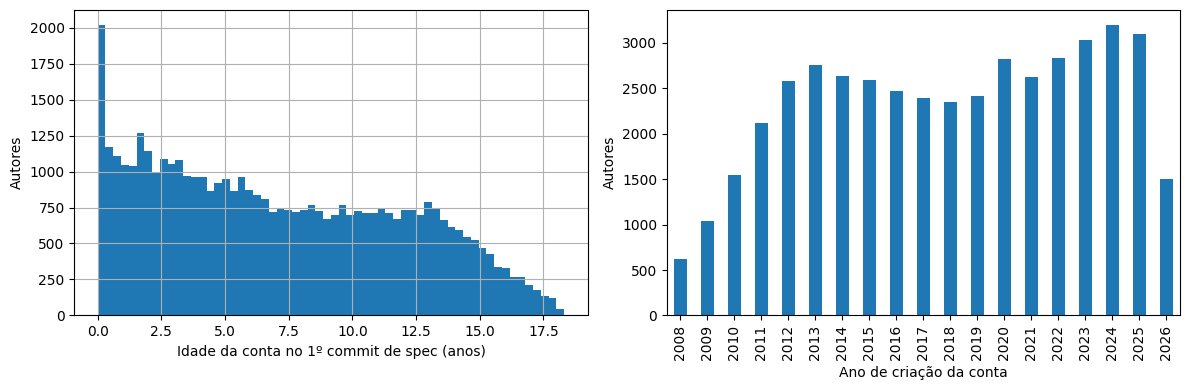

In [ ]:
# 5) Calcular idade e ver a distribuição
import matplotlib.pyplot as plt

feitos = pd.read_csv(OUT)
df = autores.merge(feitos, on='author_id')
df['created_at'] = pd.to_datetime(df['created_at'], utc=True)
df['idade_anos'] = (df.primeiro_commit - df.created_at).dt.days / 365.25
df['idade_anos'] = df.idade_anos.clip(lower=0)   # commit local anterior à conta: idade = 0 (ponto 19)

print(df.idade_anos.describe(percentiles=[.1, .25, .5, .75, .9]).round(2))
print('\nAno de criação das contas:')
print(df.created_at.dt.year.value_counts().sort_index())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.idade_anos.hist(bins=60, ax=ax[0])
ax[0].set(xlabel='Idade da conta no 1º commit de spec (anos)', ylabel='Autores')
df.created_at.dt.year.value_counts().sort_index().plot.bar(ax=ax[1])
ax[1].set(xlabel='Ano de criação da conta', ylabel='Autores')
plt.tight_layout(); plt.savefig(os.path.join(DATA, 'dist_idade_contas.png'), dpi=200); plt.show()

df.to_csv(os.path.join(DATA, 'autores_idade.csv'), index=False)

# Quando escolher o corte:
# X_ANOS = ...
# df['grupo'] = (df.idade_anos >= X_ANOS).map({True: 'mais_antiga', False: 'mais_nova'})
# print(df.grupo.value_counts())

## Idade no primeiro uso de SDD (versão corrigida, ponto 14)
Usa a data de criação da spec (`spec_files.file_first_commit_at`). Gera `data/autores_idade_v2.csv`. Pré-requisito: células 1 e 2 e a linha do `OUT`.

In [6]:
# 7) Idade da conta no PRIMEIRO USO DE SDD = data de criação da spec (ponto 14)
#    Usa spec_files.file_first_commit_at, em vez do 1º commit do histórico do arquivo.
HF = 'https://huggingface.co/api/datasets/ShyAgarwal/specmine/parquet/{}/train/0.parquet'
sf = pd.read_parquet(HF.format('spec_files'), columns=[
    'file_first_commit_author_id', 'file_first_commit_author_type',
    'file_first_commit_author_login', 'file_first_commit_at'])
sf = sf[(sf.file_first_commit_author_type == 'User')
        & sf.file_first_commit_author_id.notna()
        & ~sf.file_first_commit_author_login.fillna('').str.endswith('[bot]')].copy()
sf['t0'] = pd.to_datetime(sf.file_first_commit_at, utc=True, errors='coerce')
sf = sf[sf.t0 <= pd.Timestamp('2026-11-15', tz='UTC')]   # descarta datas no futuro

uso = (sf.groupby('file_first_commit_author_id').t0.min()
         .rename('primeiro_uso_sdd').reset_index()
         .rename(columns={'file_first_commit_author_id': 'author_id'}))
uso['author_id'] = uso.author_id.astype('int64')

contas = pd.read_csv(OUT)
contas['created_at'] = pd.to_datetime(contas.created_at, utc=True)
idade = uso.merge(contas, on='author_id', how='left')
sem_data = idade.created_at.isna().sum()
idade = idade.dropna(subset=['created_at'])
idade['idade_anos'] = (idade.primeiro_uso_sdd - idade.created_at).dt.days / 365.25
negativos = (idade.idade_anos < 0).sum()
idade['idade_anos'] = idade.idade_anos.clip(lower=0)   # commit local anterior à conta: idade = 0 (ponto 19)

print(f'criadores de spec: {len(uso)} | sem data da conta: {sem_data} | idade zerada: {negativos}')
print(idade.idade_anos.describe(percentiles=[.1, .25, .5, .75, .9]).round(2))
print('primeiro uso de SDD antes de 2025:', (idade.primeiro_uso_sdd < '2025-01-01').mean().round(3))

idade.to_csv(os.path.join(DATA, 'autores_idade_v2.csv'), index=False)

criadores de spec: 38803 | sem data da conta: 182 | idade zerada: 107
count    38621.00
mean         7.37
std          4.91
min          0.00
10%          1.04
25%          2.98
50%          6.88
75%         11.56
90%         14.26
max         18.46
Name: idade_anos, dtype: float64
primeiro uso de SDD antes de 2025: 0.022


In [7]:
s = (pd.read_parquet(HF.format('spec_files'), columns=['file_url_sha16', 'file_first_commit_author_id', 'file_first_commit_author_type'])
       .merge(pd.read_parquet(HF.format('spec_content_features'), columns=['file_url_sha16', 'content_family', 'lang']), on='file_url_sha16'))
s = s[(s.lang == 'en') & s.content_family.isin(['openspec', 'speckit']) & (s.file_first_commit_author_type == 'User')]
s = s[s.file_first_commit_author_id.isin(idade.author_id)]
print(s.groupby('content_family').agg(specs=('file_url_sha16', 'size'), autores=('file_first_commit_author_id', 'nunique')))
print('total:', len(s), 'specs |', s.file_first_commit_author_id.nunique(), 'autores únicos')

                 specs  autores
content_family                 
openspec        179566     5735
speckit          36264     6296
total: 215830 specs | 11782 autores únicos


In [ ]:
# 6) Specs "unknown" (sem template reconhecido) vs. com template
import pandas as pd, os
HF = 'https://huggingface.co/api/datasets/ShyAgarwal/specmine/parquet/{}/train/0.parquet'

sf = pd.read_parquet(HF.format('spec_files'), columns=[
    'file_url_sha16', 'spec_tool', 'file_first_commit_author_id',
    'file_first_commit_author_type', 'file_first_commit_at'])
cf = pd.read_parquet(HF.format('spec_content_features'), columns=[
    'file_url_sha16', 'content_family', 'lang', 'has_ears', 'has_edge_cases',
    'has_user_story', 'has_unfilled_placeholder', 'n_words'])
s = sf.merge(cf, on='file_url_sha16')
s['t0'] = pd.to_datetime(s.file_first_commit_at, utc=True, errors='coerce')

print('== Por família de template: specs, autores, % antes de 2025, % inglês')
print(s.groupby('content_family').agg(
    specs=('file_url_sha16', 'size'),
    autores=('file_first_commit_author_id', 'nunique'),
    pct_antes_2025=('t0', lambda x: round(100 * (x < '2025-01-01').mean(), 1)),
    pct_en=('lang', lambda x: round(100 * (x == 'en').mean(), 1)),
).sort_values('specs', ascending=False))

u = s[s.content_family == 'unknown']
print('\n== Ferramenta (spec_tool) dentro de unknown')
print(u.spec_tool.value_counts(normalize=True).mul(100).round(1).head(15))

print('\n== Features dentro de unknown, por ferramenta (%)')
print(u.groupby('spec_tool').agg(
    specs=('file_url_sha16', 'size'),
    ears=('has_ears', lambda x: round(100 * x.mean(), 1)),
    edge=('has_edge_cases', lambda x: round(100 * x.mean(), 1)),
    user_story=('has_user_story', lambda x: round(100 * x.mean(), 1)),
    palavras_mediana=('n_words', 'median'),
).sort_values('specs', ascending=False).head(10))

# Idade dos criadores: só unknown x misto x só template
idade = pd.read_csv(os.path.join(DATA, 'autores_idade.csv'))[['author_id', 'idade_anos']]
h = s[s.file_first_commit_author_type == 'User']
per = h.groupby('file_first_commit_author_id').content_family.agg(
    so_unknown=lambda x: (x == 'unknown').all(),
    algum_unknown=lambda x: (x == 'unknown').any()).reset_index()
per['grupo'] = per.apply(lambda r: 'so_unknown' if r.so_unknown
                         else ('misto' if r.algum_unknown else 'so_template'), axis=1)
per = per.merge(idade, left_on='file_first_commit_author_id', right_on='author_id')
print('\n== Idade da conta (anos) por grupo de criador')
print(per.groupby('grupo').idade_anos.describe(percentiles=[.25, .5, .75]).round(2))

== Por família de template: specs, autores, % antes de 2025, % inglês
                 specs  autores  pct_antes_2025  pct_en
content_family                                         
openspec        216384     6182             0.0    92.5
unknown         199181    31501             0.8    89.3
speckit          44587     6948             0.0    91.2
caffeine          7264       13             0.0    98.2
agent_os           667       93             0.0    88.8
moai               224       17             0.0    94.2

== Ferramenta (spec_tool) dentro de unknown
spec_tool
openspec         34.4
adhoc_other      18.3
specs_generic     9.8
docs_embedded     9.6
root_bare         8.4
speckit           7.6
conductor         3.9
caffeine          3.6
opencode          1.0
dot_specs         0.7
claude_code       0.7
specweave         0.5
moai              0.5
agent_os          0.3
codex             0.3
Name: proportion, dtype: float64

== Features dentro de unknown, por ferramenta (%)
             

NameError: name 'DATA' is not defined